# Finite difference solver for a toy BVP

Companion notebook for Example 16.1 in `Lec16.tex`. We solve
$$
u''(t) = f(t), \qquad u(0) = c_0, \quad u(1) = c_1,
$$
where $f$ is a narrow Gaussian bump of standard deviation $\sigma = 0.1$ centered at $t = 1/2$,
$$
f(t) = \exp\!\left(-\frac{(t - 1/2)^2}{2\sigma^2}\right),
$$
and we take homogeneous boundary conditions $c_0 = c_1 = 0$.

Following the three steps of the lecture:
- **Step 1:** uniform grid $t_n = n \Delta t$, $n = 0, \dots, N$, with $\Delta t = 1/N$.
- **Step 2:** approximate $u''(t_n) \approx \frac{u_{n-1} - 2u_n + u_{n+1}}{\Delta t^2}$.
- **Step 3:** assemble the $(N+1) \times (N+1)$ linear system $A \mathbf{u} = \mathbf{f}$, whose first and last rows
  enforce $u_0 = c_0$ and $u_N = c_1$, and solve it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf

In [2]:
sigma = 0.1
m = 0.5
c0, c1 = 0.0, 0.0


def f(t):
    return -np.exp(-((t - m) ** 2) / (2 * sigma**2))


def fd_solve(f, N, c0, c1):
    t = np.linspace(0, 1, N + 1)
    dt = 1 / N

    A = np.zeros((N + 1, N + 1))
    b = f(t)
    # boundary rows: u_0 = c0 and u_N = c1
    A[0, 0] = 1
    A[N, N] = 1
    b[0], b[N] = c0, c1
    # interior rows: (u_{n-1} - 2 u_n + u_{n+1}) / dt^2 = f_n
    for n in range(1, N):
        A[n, n - 1] = 1 / dt**2
        A[n, n] = -2 / dt**2
        A[n, n + 1] = 1 / dt**2

    u = np.linalg.solve(A, b)
    return t, u

For reference we also compute the exact solution. Integrating $f$ twice gives the particular solution
$$
H(t) = \sigma\sqrt{\tfrac{\pi}{2}}\,(t - m)\,\mathrm{erf}\!\left(\frac{t - m}{\sqrt{2}\sigma}\right) + \sigma^2 \exp\!\left(-\frac{(t-m)^2}{2\sigma^2}\right),
$$
with $m = 1/2$, and $u(t) = H(t) + \alpha t + \beta$ with $\alpha, \beta$ chosen to match the boundary conditions.

In [3]:
def H(t):
    return -sigma * np.sqrt(np.pi / 2) * (t - m) * erf((t - m) / (np.sqrt(2) * sigma)) + sigma**2 * f(t)


def u_exact(t):
    beta = c0 - H(0)
    alpha = c1 - H(1) - beta
    return H(t) + alpha * t + beta

N =   4: max error = 1.258e-02
N =   8: max error = 1.432e-03
N =  16: max error = 3.322e-04


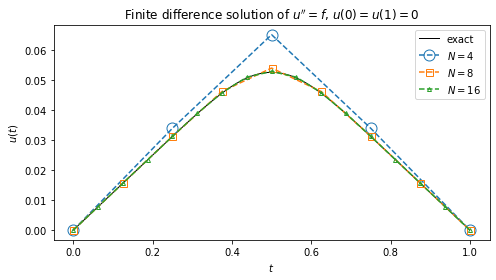

In [4]:
t_fine = np.linspace(0, 1, 500)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_fine, u_exact(t_fine), "k-", linewidth=1, label="exact")
# nested grids share points, so use hollow markers of decreasing size to keep all visible
for N, marker, ms in zip([4, 8, 16], ["o", "s", "^"], [11, 7, 4]):
    t, u = fd_solve(f, N, c0, c1)
    err = np.max(np.abs(u - u_exact(t)))
    print(f"N = {N:3d}: max error = {err:.3e}")
    ax.plot(t, u, marker=marker, linestyle="--", markersize=ms, markerfacecolor="none", label=rf"$N = {N}$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$u(t)$")
ax.set_title(r"Finite difference solution of $u'' = f$, $u(0) = u(1) = 0$")
ax.legend()
fig.tight_layout()
fig.savefig("fd_toy_bvp.png", dpi=300, bbox_inches="tight")
plt.show()

The error drops by roughly a factor of 4 each time $N$ is doubled, consistent with the second order accuracy of the
centered difference formula for $u''$. On the coarsest grid $N = 8$ the spacing $\Delta t = 0.125$ is larger than the
width $\sigma$ of the bump, so the forcing is poorly resolved, yet the solution is already qualitatively correct.

## Convergence study

We measure the maximum error $E_N = \max_n |u_n - u(t_n)|$ over a sequence of grids $N = 4, 8, \dots, 1024$.
If $E_N \approx C N^{-p}$ then $\log E_N \approx \log C - p \log N$, so the rate $p$ is minus the slope of the
error on a log-log plot. We estimate $p$ in two ways: from the ratio of successive errors,
$p \approx \log_2(E_N / E_{2N})$, and from a least squares fit of a line to $(\log N, \log E_N)$.

In [5]:
Ns = 2 ** np.arange(2, 11)
errs = np.array([np.max(np.abs(u - u_exact(t))) for t, u in (fd_solve(f, N, c0, c1) for N in Ns)])

# observed rate between successive grids
rates = np.log2(errs[:-1] / errs[1:])
print(f"{'N':>6} {'max error':>12} {'rate':>6}")
print(f"{Ns[0]:6d} {errs[0]:12.3e}")
for N, e, r in zip(Ns[1:], errs[1:], rates):
    print(f"{N:6d} {e:12.3e} {r:6.2f}")

# least squares fit of log(err) = log(C) - p log(N); skip N = 4, which does not resolve the bump
slope, intercept = np.polyfit(np.log(Ns[1:]), np.log(errs[1:]), 1)
p = -slope
print(f"\nfitted rate of convergence: p = {p:.3f}")

     N    max error   rate
     4    1.258e-02
     8    1.432e-03   3.13
    16    3.322e-04   2.11
    32    8.178e-05   2.02
    64    2.037e-05   2.01
   128    5.088e-06   2.00
   256    1.272e-06   2.00
   512    3.179e-07   2.00
  1024    7.947e-08   2.00

fitted rate of convergence: p = 2.013


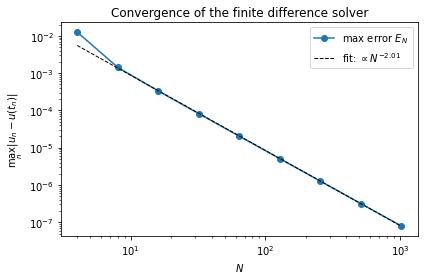

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, errs, "o-", label=r"max error $E_N$")
ax.loglog(Ns, np.exp(intercept) * Ns.astype(float) ** slope, "k--", linewidth=1, label=rf"fit: $\propto N^{{-{p:.2f}}}$")
ax.set_xlabel(r"$N$")
ax.set_ylabel(r"$\max_n |u_n - u(t_n)|$")
ax.set_title("Convergence of the finite difference solver")
ax.legend()
fig.tight_layout()
fig.savefig("fd_toy_bvp_convergence.png", dpi=300, bbox_inches="tight")
plt.show()